<a href="https://colab.research.google.com/github/ZackyRioOrlando/Praktikum-Pembelajaran-Mesin-/blob/main/JS10/JS10_04.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

🌻
Lab 4

Klasifikasi Siang dan Malang dengan ANN

Langkah 1 - Import Library

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [24]:
	from pathlib import Path
	import numpy as np
	import matplotlib.pyplot as plt
	import cv2

	from skimage.feature import hog
	from sklearn.preprocessing import StandardScaler
	from sklearn.model_selection import train_test_split
	from sklearn.metrics import confusion_matrix, classification_report

	import tensorflow as tf
	from tensorflow.keras import layers, models

Langkah 2 - Load Dataset

In [25]:
	# Load images and labels from a directory structure
	def load_dataset(img_dir):
	    p = Path(img_dir)
	    img_list = []
	    for folder in p.glob('*'):
	        label = folder.name
	        for file in folder.glob('*.jpg'):
	            img = cv2.imread(str(file))
	            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
	            img_list.append((img, label))
	    return img_list

	train_dir = "/content/drive/MyDrive/images/images/training/"
	test_dir  = "/content/drive/MyDrive/images/images/test/"

	train_img = load_dataset(train_dir)
	test_img  = load_dataset(test_dir)

Langkah 2 - Pra Pengolahan

In [27]:
	# Preprocess images: resize and encode labels
	def resize_image(img, size=(256,256)):
	    return cv2.resize(img, size)

	def label_encoder(label):
	    return 1 if label == 'day' else 0

	def preprocess(img_list):
	    X = []
	    y = []
	    for img, label in img_list:
	        img_std = resize_image(img)
	        X.append(img_std)
	        y.append(label_encoder(label))
	    return X, y

	X_train_img, y_train = preprocess(train_img)
	X_test_img,  y_test  = preprocess(test_img)

Langkah 3 - Ekstraksi Fitur

In [28]:
	# Extract HOG features
	def extract_hog(X_imgs):
	    feats = []
	    for img in X_imgs:
	        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
	        hog_feat = hog(gray,
	                       orientations=9,
	                       pixels_per_cell=(8,8),
	                       cells_per_block=(2,2),
	                       block_norm='L2-Hys',
	                       visualize=False,
	                       feature_vector=True)
	        feats.append(hog_feat)
	    return np.array(feats)

	X_train_feat = extract_hog(X_train_img)
	X_test_feat  = extract_hog(X_test_img)

Langkah 4 - Standardisasi Fitur

In [29]:
	# Normalize features
	scaler = StandardScaler()
	X_train_scaled = scaler.fit_transform(X_train_feat)
	X_test_scaled  = scaler.transform(X_test_feat)

Langkah 5 - Buat Data Latih dan Validasi

In [30]:
	X_train, X_val, y_train, y_val = train_test_split(
	    X_train_scaled, y_train,
	    test_size=0.2,
	    random_state=42
	)

	# Convert label ke numpy array
	y_train = np.array(y_train)
	y_val   = np.array(y_val)
	y_test  = np.array(y_test)

Langkah 6 - Buat Model ANN
Arsitektur model yang digunakan adalah,

- Input Layer

- Hidden Layer 1 - 128 Nodes - ReLU

- Hidden Layer 2 - 64 Nodes - ReLu

- Output Layer - 2 Nodes - Sigmoid

In [31]:
	input_dim = X_train.shape[1]

	model = models.Sequential([
	    layers.Input(shape=(input_dim,)),
	    layers.Dense(128, activation='relu'),
	    layers.Dense(64, activation='relu'),
	    layers.Dense(1, activation='sigmoid')
	])

	model.compile(
	    optimizer='adam',
	    loss='binary_crossentropy',
	    metrics=['accuracy']
	)

	model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

Langkah 7 - Latih Model

In [32]:
	history = model.fit(
	    X_train, y_train,
	    epochs=20,
	    batch_size=32,
	    validation_data=(X_val, y_val)
	)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 251ms/step - accuracy: 0.7708 - loss: 1.2149 - val_accuracy: 0.9167 - val_loss: 0.7394
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 140ms/step - accuracy: 0.9792 - loss: 0.2444 - val_accuracy: 0.9583 - val_loss: 0.1688
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 105ms/step - accuracy: 0.9948 - loss: 0.0232 - val_accuracy: 0.9792 - val_loss: 0.0161
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 128ms/step - accuracy: 0.9948 - loss: 0.0047 - val_accuracy: 0.9792 - val_loss: 0.0439
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - accuracy: 1.0000 - loss: 1.4493e-05 - val_accuracy: 0.9792 - val_loss: 0.0753
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 99ms/step - accuracy: 1.0000 - loss: 4.1056e-06 - val_accuracy: 0.9792 - val_loss: 0.0969
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step - accuracy: 1.0000 - loss: 4.4812e-06 - val_accuracy: 0.9792 - val_loss: 0.1099
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 145ms/step - accuracy: 1.0000 - loss: 1.0922e-05 - val_accuracy: 0.97

Langkah 8 - Evaluasi Model dengan Data Test

In [33]:
	test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
	print("Akurasi Test:", test_acc)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.8938 - loss: 0.9932
Akurasi Test: 0.893750011920929


Langkah 9 - Buat Laporan Performansi Model

In [34]:
	y_pred_prob = model.predict(X_test_scaled)
	y_pred = (y_pred_prob > 0.5).astype(int)

	print(classification_report(y_test, y_pred))
	print(confusion_matrix(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
              precision    recall  f1-score   support

           0       0.97      0.81      0.88        80
           1       0.84      0.97      0.90        80

    accuracy                           0.89       160
   macro avg       0.90      0.89      0.89       160
weighted avg       0.90      0.89      0.89       160

[[65 15]
 [ 2 78]]


Langkah 10 - Visualisasi Proses Training

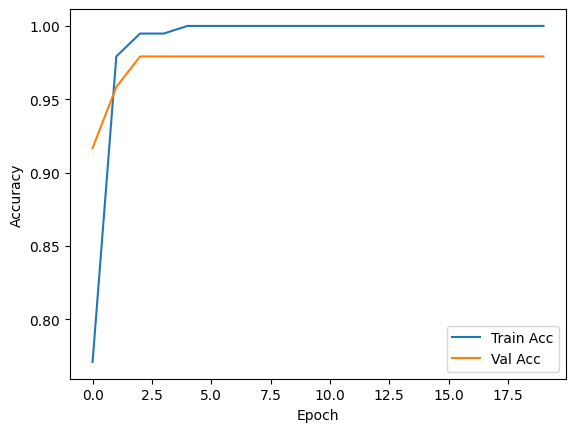

In [35]:
	plt.plot(history.history['accuracy'], label='Train Acc')
	plt.plot(history.history['val_accuracy'], label='Val Acc')
	plt.xlabel('Epoch')
	plt.ylabel('Accuracy')
	plt.legend()
	plt.show()

Dari grafik tersebut, apa yang bisa Anda interpretasikan?

Berdasarkan grafik, model mengalami peningkatan akurasi yang cepat pada awal proses training. Akurasi training meningkat dari sekitar 77% hingga mencapai 100%, sedangkan akurasi validasi mencapai sekitar 98%. Setelah beberapa epoch, kedua nilai akurasi cenderung stabil. Hal ini menunjukkan bahwa model mampu mempelajari pola data dengan baik, memiliki performa yang tinggi, dan tidak menunjukkan indikasi overfitting yang signifikan.

Langkah 11 - Simpan Model

In [36]:
model.save('day_night_classifier_model.h5')